# Experimento A/B en una página de inicio

**¿Qué versión de la landing page conviene más al negocio? Pruebas de hipótesis sobre 40,000 usuarios expuestos a las versiones A y B.**

<a href="https://colab.research.google.com/github/fvt1999pipe-eng/analisis_experimento_ab/blob/main/analisis_experimento_ab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

**Autor:** Felipe Vásquez Torres · [LinkedIn](https://www.linkedin.com/in/felipe-vasquez-torres) · [Portafolio](https://fvt1999pipe-eng.github.io)

## Contexto y objetivo

Una empresa probó dos versiones de su página de inicio (**A** y **B**) durante cuatro semanas. El objetivo es evaluar el experimento con pruebas estadísticas y **recomendar qué versión usar**, con una decisión basada en datos.

## Datos

| Archivo | Filas | Contenido |
|---|---|---|
| `landing_experiment.csv` | 40,000 | Un registro por usuario con 9 columnas: versión de la página, fecha de exposición, región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto. |

## Contenido

1. Carga y validación de los datos
2. Gasto promedio por usuario: página A frente a B (prueba t de Welch)
3. Tasa de conversión: página A frente a B (prueba Z de dos proporciones)
4. Fuente de tráfico y conversión (chi-cuadrado de independencia)
5. Tipo de usuario y conversión (chi-cuadrado de independencia)
6. Visualización de los resultados
7. Conclusiones y recomendaciones para el negocio

---
## 1. Carga y validación de los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# Librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import levene

In [2]:
# Cargar el dataset
df = pd.read_csv('datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [3]:
# Primeras 5 filas
df.head(5)

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# Estructura y tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Hallazgos de la revisión inicial**

- El dataset tiene **40 000 filas y 9 columnas**, sin valores ausentes: todas las columnas registran 40 000 valores no nulos.
- La columna `date` es de tipo `object`. Podría convertirse a fecha con `pd.to_datetime()`, pero no es necesario porque el análisis no incluye tendencias en el tiempo.
- Las columnas `landing`, `region`, `dispositivo`, `traffic_source` y `user_type` son de tipo `object`. Son variables categóricas con pocos valores posibles.
- `user_id` es `object`, lo cual es correcto por tratarse de un identificador tipo UUID.
- `converted` es `int64` con valores 0/1 y `gasto` es `float64`; ambos tipos son adecuados.
- Los nombres de columnas están en snake_case y no requieren corrección.

**Pasos a seguir**

1. Verificar filas duplicadas y `user_id` repetidos (un usuario no debería aparecer en ambas versiones de `landing`).
2. Validar la coherencia entre `converted` y `gasto`: gasto igual a 0 cuando no hay conversión, mayor a 0 cuando la hay, y sin valores negativos.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.

**Variable `user_id`**: verificar que los usuarios sean únicos.

In [5]:
df["user_id"].nunique()

40000

**Variable `date`**: rango de fechas del experimento.

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [8]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [9]:
# Resumen estadístico de usuarios que se convirtieron
df[(df['converted']==1)]["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

**Variable `landing`**: verificar que solo existan las versiones esperadas (A y B).

In [10]:
# Usuarios por versión de la página
print("\nConteo de categorías:")
print(df.groupby("landing")["user_id"].count())


Conteo de categorías:
landing
A    19982
B    20018
Name: user_id, dtype: int64


In [11]:
df["landing"].value_counts(normalize=True) * 100

B    50.045
A    49.955
Name: landing, dtype: float64

**Hallazgos del análisis exploratorio**

- **`user_id`**: hay 40 000 identificadores únicos en 40 000 filas, por lo que no existen usuarios duplicados y cada usuario pertenece a un solo grupo del experimento.
- **`date`**: el experimento abarca 28 días consecutivos, del 2026-01-01 al 2026-01-28 (4 semanas completas). El día con más registros es el 2026-01-24, con 1 512 usuarios, cercano al promedio diario de 1 429.
- **`gasto`**: no hay valores negativos (mínimo 0). Más del 75 % de los registros tiene gasto 0, lo cual es esperado porque la mayoría de los usuarios no convirtió. El gasto total coincide con el de los usuarios convertidos, lo que confirma que quienes no convirtieron tienen gasto 0.
- **Usuarios convertidos**: 5 706 usuarios convirtieron, una tasa global de 14,3 %. Todos tienen gasto mayor a 0 (mínimo 12,12), con una media de 65,37 y una mediana de 59,86. La distribución tiene sesgo a la derecha: el máximo de 303,68 está muy por encima del tercer cuartil (80,37) y supera el límite de 136,50 del criterio de 1,5 × IQR, por lo que existen valores atípicos altos.
- **`landing`**: solo aparecen las dos categorías esperadas, A (19 982 usuarios) y B (20 018 usuarios). Los grupos están balanceados, con una diferencia de apenas 36 usuarios.

**Pasos a seguir**

1. Tener en cuenta los valores atípicos de `gasto` al comparar el gasto promedio entre grupos, ya que pueden distorsionar la media.
2. No se requieren correcciones en las variables revisadas: todas tienen valores esperados.

---
## 2. Gasto promedio por usuario: página A frente a B

Se evalúa si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.

In [12]:
# Gasto por versión
gasto_A = df[(df['landing']== "A") & (df['converted']== 1)]["gasto"]

gasto_B = df[(df['landing']== "B") & (df['converted']== 1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
print(len(gasto_A), len(gasto_B))

# Verificar promedio del gasto por grupo
print(f"Gasto promedio A: {gasto_A.mean()}")
print(f"Gasto promedio B: {gasto_B.mean()}")

2512 3194
Gasto promedio A: 61.0865724522293
Gasto promedio B: 68.74536005009392


### Prueba t para muestras independientes

Se compara el gasto promedio entre dos grupos independientes: los usuarios expuestos a la landing A y los expuestos a la landing B.

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios de la landing A es igual al gasto promedio de los usuarios de la landing B (μ_A = μ_B).
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios de la landing A es diferente al gasto promedio de los usuarios de la landing B (μ_A ≠ μ_B).

**Nivel de significancia:** α = 0,05. Si el valor p es menor que α, se rechaza la hipótesis nula.

In [13]:
# Ejecutar prueba de Levene y mostrar resultados
l_stat, p_value_var = levene(gasto_A, gasto_B)

# Visualizar resultados
print(f"Estadístico de Levene: {l_stat}")
print(f"Valor p: {p_value_var}")

alpha = 0.05  # umbral de significancia
if p_value_var < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")

Estadístico de Levene: 29.17646453202917
Valor p: 6.875301988016449e-08
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).


In [14]:
# Aplicar prueba
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var = False)

# Visualizar resultados
print(f"Estadístico t: {t_stat}")
print(f"Valor p: {p_value}")

Estadístico t: -9.48101092267275
Valor p: 3.627602231521493e-21


In [15]:
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia estadística de una diferencia en el gasto promedio entre las páginas A y B.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia en el gasto promedio entre las páginas A y B.")

Rechazamos la hipótesis nula: hay evidencia estadística de una diferencia en el gasto promedio entre las páginas A y B.


### Conclusión e interpretación

**Decisión:**
Se rechaza la hipótesis nula. El valor p (3,63 × 10⁻²¹) es menor que el umbral de 0,05, por lo que el resultado es estadísticamente significativo (estadístico t = −9,48).

La prueba de Levene indicó varianzas diferentes entre los grupos (estadístico = 29,18; p < 0,001), por lo que la prueba t se aplicó sin asumir varianzas iguales (versión de Welch).

**Interpretación de negocio:**
Con base en una prueba t de dos muestras independientes, encontramos evidencia estadística de que el gasto promedio de los usuarios que convirtieron difiere entre las páginas A y B. Si en realidad no existiera diferencia, sería muy poco probable observar datos como estos.

En promedio, los usuarios que convirtieron en la página B gastaron 68,75, frente a 61,09 de los que convirtieron en la página A: una diferencia de 7,66, equivalente a un 12,5 % más.

Este resultado se basa en los 5 706 usuarios que realizaron una compra entre el 1 y el 28 de enero de 2026 (2 512 en la página A y 3 194 en la página B) y asume observaciones independientes. El gasto presenta valores atípicos altos que pueden influir en los promedios. La significancia estadística no garantiza que el diseño de la página sea la única causa de la diferencia, ni evalúa si esta es suficiente para justificar un cambio desde una perspectiva de negocio.

---
## 3. Tasa de conversión: página A frente a B

Se evalúa si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z para comparar proporciones

Se compara la tasa de conversión entre dos grupos independientes: los usuarios expuestos a la página A y los expuestos a la página B.

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión de la página A es igual a la tasa de conversión de la página B (p_A = p_B).
- **Hipótesis alternativa (H₁):** La tasa de conversión de la página A es diferente a la tasa de conversión de la página B (p_A ≠ p_B).

**Nivel de significancia:** α = 0,05. Si el valor p es menor que α, se rechaza la hipótesis nula.

In [16]:
# Número de usuarios convertidos por página
con_A = df[(df['landing']== "A") & (df['converted']== 1)]["user_id"].count()

con_B = df[(df['landing']== "B") & (df['converted']== 1)]["user_id"].count()

# Total de usuarios por página

total_A = df[(df['landing']== "A")]["user_id"].count()

total_B = df[(df['landing']== "B")]["user_id"].count()

print("Usuarios convertidos por página A:\n",con_A)
print("\nTotal de usuarios por página A:\n", total_A)
print()
print("Usuarios convertidos por página B:\n",con_B)
print("\nTotal de usuarios por página B:\n", total_B)

Usuarios convertidos por página A:
 2512

Total de usuarios por página A:
 19982

Usuarios convertidos por página B:
 3194

Total de usuarios por página B:
 20018


In [17]:
tasa_A = con_A/total_A *100
tasa_B = con_B/total_B *100

print("Tasa de conversion por página A:\n",tasa_A)

print("Tasa de conversion por página B:\n",tasa_B)

Tasa de conversion por página A:
 12.571314182764487
Tasa de conversion por página B:
 15.955639924068338


In [18]:
# Aplicar prueba
conversion = [con_A, con_B]
total = [total_A, total_B]
z_stat, p_value = proportions_ztest(conversion , total)

# Visualizar resultados
print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")

alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

Estadístico z: -9.677362674655983
Valor p: 3.7629765627523803e-22
Rechazamos la hipótesis nula: hay evidencia de una diferencia.


### Conclusión e interpretación

**Decisión:**
Se rechaza la hipótesis nula. El valor p (3,76 × 10⁻²²) es menor que el umbral de 0,05, por lo que el resultado es estadísticamente significativo (estadístico Z = −9,68).

**Interpretación de negocio:**
Con base en una prueba Z de dos proporciones, encontramos evidencia estadística de que la tasa de conversión difiere entre las páginas A y B. Si en realidad no existiera diferencia, sería muy poco probable observar datos como estos.

En la muestra, la página B convirtió una mayor proporción de usuarios: 15,96 % (3 194 de 20 018) frente a 12,57 % (2 512 de 19 982) en la página A, una diferencia de 3,38 puntos porcentuales.

Este resultado se basa en una muestra de 40 000 usuarios observados entre el 1 y el 28 de enero de 2026 y asume observaciones independientes. La significancia estadística no garantiza que el diseño de la página sea la única causa de la diferencia, ni evalúa si esta es suficiente para justificar un cambio desde una perspectiva de negocio.

---
## 4. Fuente de tráfico y conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi-cuadrado de independencia

Se evalúa si existe asociación entre dos variables categóricas: la fuente de tráfico (`traffic_source`) y la conversión (`converted`).

**Hipótesis:**
- **Hipótesis nula (H₀):** La fuente de tráfico y la conversión son independientes; la tasa de conversión es la misma en todos los canales.
- **Hipótesis alternativa (H₁):** La fuente de tráfico y la conversión están asociadas; la tasa de conversión difiere en al menos un canal.

**Nivel de significancia:** α = 0,05. Si el valor p es menor que α, se rechaza la hipótesis nula.

In [19]:
# Tabla de contingencia normalizada
tabla_nor = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
print(tabla_nor)

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163


In [20]:
# Tabla de contingencia para prueba Chi2
tabla = pd.crosstab(df['traffic_source'], df['converted'])

chi2_stat, p_value, dof, expected = chi2_contingency(tabla)
print(f"\nEstadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Valor dof: {dof:.3f}")
# Interpretar el resultado
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")


Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Valor dof: 3.000
Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.


In [21]:
# Conteo de usuarios por canal y conversión

print(tabla)

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


### Conclusión e interpretación
**Decisión:**
Se rechaza la hipótesis nula. El valor p (0,034) es menor que el umbral de 0,05, por lo que el resultado es estadísticamente significativo (chi-cuadrado = 8,66 con 3 grados de libertad).

**Interpretación de negocio:**
Con base en una prueba chi-cuadrado de independencia, encontramos evidencia estadística de una asociación entre la fuente de tráfico y la conversión. La evidencia es moderada: el resultado es significativo al 5 %, pero no lo sería con un umbral más estricto del 1 %.

- **Tasas de conversión:** Email (14,99 %) y Ads (14,74 %) presentan las tasas más altas, mientras que Referral (13,88 %) y Organic (13,79 %) las más bajas. La diferencia entre el canal más alto y el más bajo es de 1,2 puntos porcentuales.
- **Cantidades absolutas:** Organic es el canal que más conversiones aporta (2 480, el 43,5 % del total) a pesar de tener la tasa más baja, porque concentra el mayor volumen de usuarios (17 987). Le siguen Ads (1 759 conversiones), Email (918) y Referral (549). Email tiene la mejor tasa, pero su volumen de usuarios (6 123) es cerca de un tercio del de Organic.

En conjunto, el canal que convierte en mayor proporción no es el que genera más conversiones: el volumen de tráfico pesa más que las diferencias en la tasa.

Este resultado se basa en una muestra de 40 000 usuarios observados entre el 1 y el 28 de enero de 2026. La prueba indica que existe asociación, pero no identifica entre qué canales está la diferencia ni establece causalidad, y no evalúa si una diferencia de esta magnitud es relevante para el negocio.

---
## 5. Tipo de usuario y conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba chi-cuadrado de independencia

Se evalúa si existe asociación entre dos variables categóricas: el tipo de usuario (`user_type`) y la conversión (`converted`).

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario y la conversión son independientes; la tasa de conversión es la misma para todos los tipos de usuario.
- **Hipótesis alternativa (H₁):** El tipo de usuario y la conversión están asociados; la tasa de conversión difiere entre los tipos de usuario.

**Nivel de significancia:** α = 0,05. Si el valor p es menor que α, se rechaza la hipótesis nula.

In [22]:
# Tabla de contingencia normalizada
tabla_1_nor = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
print(tabla_1_nor)

converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


In [23]:
# Tabla de contingencia para la prueba chi-cuadrado
tabla_1 = pd.crosstab(df['user_type'], df['converted'])

chi2_stat, p_value, dof, expected = chi2_contingency(tabla_1)
print(f"\nEstadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Valor dof: {dof:.3f}")
# Interpretar el resultado
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre las variables.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")


Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Valor dof: 1.000
No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.


In [24]:
# Conteo de usuarios por tipo y conversión

print(tabla_1)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


### Conclusión e interpretación

**Decisión:**
No se rechaza la hipótesis nula. El valor p (0,474) es mayor que el umbral de 0,05, por lo que el resultado no es estadísticamente significativo (chi-cuadrado = 0,51 con 1 grado de libertad).

**Interpretación de negocio:**
Con base en una prueba chi-cuadrado de independencia, no encontramos evidencia suficiente para afirmar que el tipo de usuario y la conversión estén asociados.

- **Tasas de conversión:** los usuarios nuevos convirtieron en un 14,36 % y los recurrentes en un 14,09 %. La diferencia de 0,27 puntos porcentuales es compatible con la variación esperada por azar.
- **Cantidades absolutas:** los usuarios nuevos aportan más conversiones (3 738 frente a 1 968), pero esto se explica por su volumen y no por una mayor propensión a convertir: representan el 65,1 % de los usuarios y el 65,5 % de las conversiones.

En esta muestra, ser usuario nuevo o recurrente no se relaciona con una mayor o menor probabilidad de conversión.

Este resultado se basa en una muestra de 40 000 usuarios observados entre el 1 y el 28 de enero de 2026. No rechazar la hipótesis nula no demuestra que las tasas sean idénticas; solo indica que los datos no aportan evidencia suficiente de una diferencia.

---
## 6. Visualización de los resultados

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### 6.1 Relación entre la fuente de tráfico y la conversión

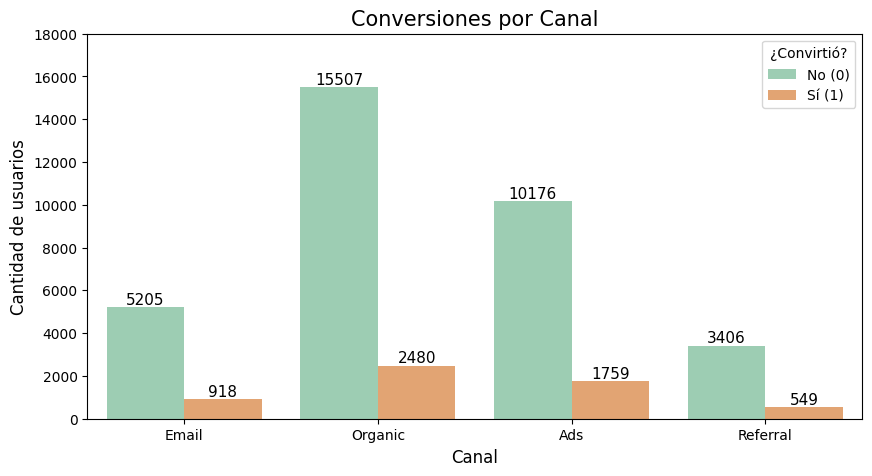

In [25]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='traffic_source', hue='converted', palette = ["#95D5B2", "#F4A261"] )

# Agregar valores
for bar in ax.patches:        # Recorrer todas las barras del gráfico
    height = bar.get_height() # Obtener altura de barra (conteo de usuarios)
    ax.text(x=bar.get_x()+bar.get_width() /2, # Establecer coordenada X del texto (centro de la barra)
            y=height,                         # Establecer coordenada Y del texto
            s=height,                         # Valor a mostrar
            ha='center',                      # Alinear centro del texto en coordenada
            va='bottom',                      # Alinear parte inferior del texto en coordenada
            fontsize=11)                      # Tamaño de la fuente

# Añadir detalles
plt.title('Conversiones por Canal', fontsize=15)
plt.xlabel('Canal', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.ylim(0,18000)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()

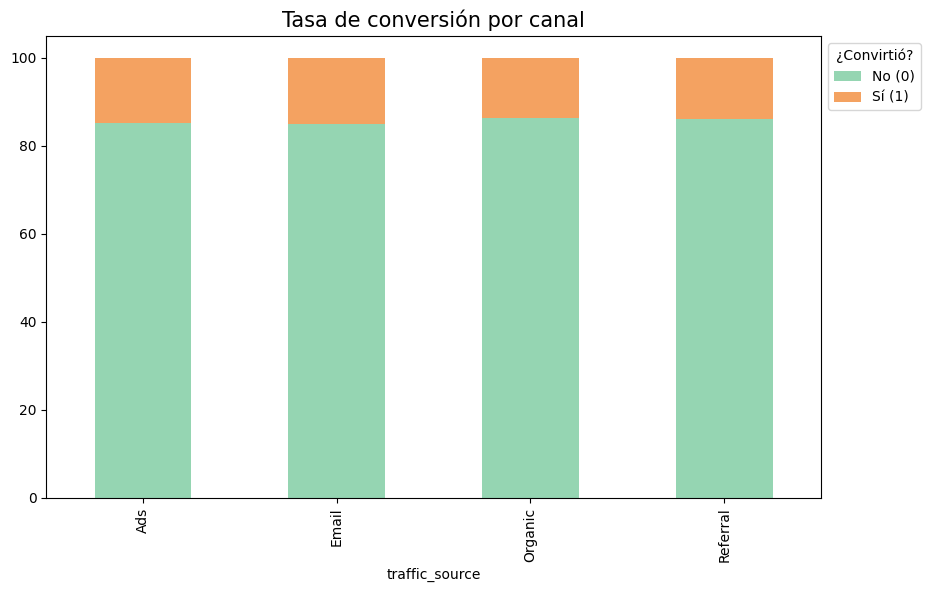

In [26]:
# Proporción de usuarios que convirtieron, por canal

tabla_nor.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#95d5b2", "#F4A261"])
plt.title('Tasa de conversión por canal', fontsize=15)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

**Hallazgos de la visualización**

- **Cantidades absolutas:** Organic concentra el mayor volumen de usuarios y también de conversiones (2 480), seguido de Ads (1 759), Email (918) y Referral (549). En todos los canales, los usuarios que no convirtieron superan ampliamente a los que sí.
- **Proporciones:** al llevar cada canal al 100 %, las barras son casi idénticas. La tasa de conversión se mueve en un rango estrecho, entre 13,8 % (Organic) y 15,0 % (Email).
- **Relación con la prueba estadística:** los gráficos refuerzan el resultado de la prueba chi-cuadrado (p = 0,034): existe una asociación estadísticamente significativa entre el canal y la conversión, pero de magnitud pequeña. Las diferencias en el número de conversiones entre canales se explican principalmente por el volumen de tráfico y no por la efectividad de cada canal.

### 6.2 Relación entre el tipo de usuario y la conversión

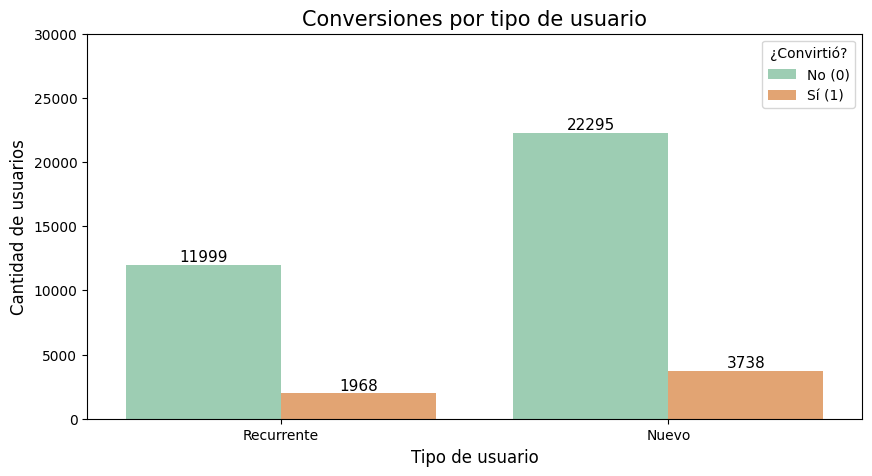

In [27]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='user_type', hue='converted', palette = ["#95D5B2", "#F4A261"] )

# Agregar valores
for bar in ax.patches:        # Recorrer todas las barras del gráfico
    height = bar.get_height() # Obtener altura de barra (conteo de usuarios)
    ax.text(x=bar.get_x()+bar.get_width() /2, # Establecer coordenada X del texto (centro de la barra)
            y=height,                         # Establecer coordenada Y del texto
            s=height,                         # Valor a mostrar
            ha='center',                      # Alinear centro del texto en coordenada
            va='bottom',                      # Alinear parte inferior del texto en coordenada
            fontsize=11)                      # Tamaño de la fuente

# Añadir detalles
plt.title('Conversiones por tipo de usuario', fontsize=15)
plt.xlabel('Tipo de usuario', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.ylim(0,30000)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()

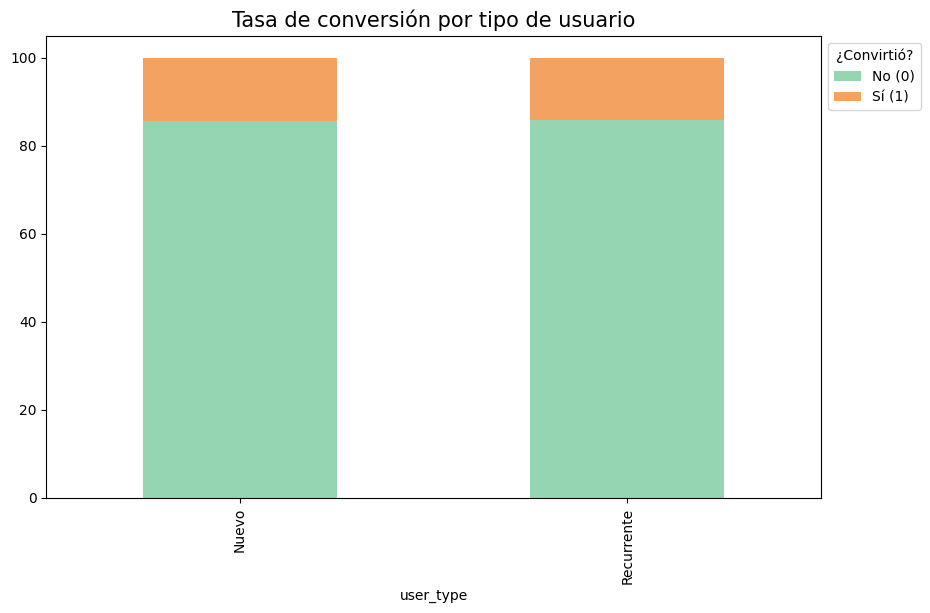

In [28]:
# Proporción de usuarios que convirtieron, por tipo de usuario
tabla_1_nor.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#95d5b2", "#F4A261"])
plt.title('Tasa de conversión por tipo de usuario', fontsize=15)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

**Hallazgos de la visualización**

- **Cantidades absolutas:** los usuarios nuevos son el grupo más grande y aportan más conversiones (3 738) que los recurrentes (1 968). En ambos grupos, los usuarios que no convirtieron superan ampliamente a los que sí.
- **Proporciones:** al llevar cada grupo al 100 %, las barras son prácticamente iguales. La tasa de conversión es de 14,4 % en usuarios nuevos y de 14,1 % en recurrentes.
- **Relación con la prueba estadística:** los gráficos son coherentes con el resultado de la prueba chi-cuadrado (p = 0,474): no hay evidencia suficiente de asociación entre el tipo de usuario y la conversión. La mayor cantidad de conversiones de los usuarios nuevos se explica por su volumen, no por una mayor propensión a convertir.

---
## 7. Conclusiones y recomendaciones para el negocio

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?

### Resumen ejecutivo

#### 🔍 **Comparación de página (A vs B)**

**Gasto promedio por usuario que convirtió:**

- Los usuarios que convirtieron en la página B gastaron en promedio 68,75, frente a 61,09 en la página A: una diferencia de 7,66 (12,5 % más).
- La diferencia es estadísticamente significativa según la prueba t (t = −9,48; p < 0,001).
- **Interpretación:** Hay evidencia de que quienes compran desde la página B gastan más por compra. Sumado a su mayor tasa de conversión, la página B aporta por dos vías: más compradores y mayor gasto de cada uno.

**Tasa de conversión:**

- La página B convirtió el 15,96 % de sus usuarios (3 194 de 20 018), frente al 12,57 % de la página A (2 512 de 19 982).
- La diferencia de 3,38 puntos porcentuales es estadísticamente significativa según la prueba Z (Z = −9,68; p < 0,001).
- **Interpretación:** La página B convierte cerca de un 27 % más que la A en términos relativos. En una base de 20 000 usuarios, esa diferencia equivale a unas 680 conversiones adicionales.

---

#### 📊 **Segmentación por fuente de tráfico**

- Email (14,99 %) y Ads (14,74 %) tienen las tasas de conversión más altas; Referral (13,88 %) y Organic (13,79 %), las más bajas. La asociación entre canal y conversión es estadísticamente significativa (chi-cuadrado, p = 0,034). En volumen, Organic aporta el 43,5 % de las conversiones (2 480).
- **Interpretación:** Los canales se diferencian poco en efectividad (1,2 puntos porcentuales entre el más alto y el más bajo). El número de conversiones de cada canal depende sobre todo de su volumen de tráfico.

---

#### 📊 **Segmentación por tipo de usuario**

- Los usuarios nuevos convirtieron en un 14,36 % y los recurrentes en un 14,09 %. La diferencia no es estadísticamente significativa (chi-cuadrado, p = 0,474).
- **Interpretación:** No hay evidencia de que el tipo de usuario influya en la conversión. Los usuarios nuevos generan más conversiones (3 738 frente a 1 968) porque son el 65 % de la base, no porque conviertan mejor.

---

Las visualizaciones de la sección 6 respaldan los resultados estadísticos de los pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**

- **Página:** priorizar la página B como versión principal, ya que supera a la A tanto en tasa de conversión como en gasto promedio. Antes de implementarla, cuantificar el impacto en ingresos y confirmar que no hubo factores externos durante el experimento, como promociones o festividades.
- **Canales:** mantener Organic como base de volumen y evaluar si es viable aumentar el tráfico de Email y Ads, que convierten ligeramente mejor. Esta decisión requiere el costo por canal, un dato que no está en el dataset.
- **Tipo de usuario:** no es necesario diferenciar la página según el tipo de usuario, porque ambos perfiles convierten de forma similar.

---

#### ⚠️ Limitaciones del análisis

- Los resultados se basan en una muestra de 40 000 usuarios observados entre el 1 y el 28 de enero de 2026, por lo que pueden no representar el comportamiento en otros periodos.
- La significancia estadística no garantiza que el diseño de la página sea la única causa de las diferencias, ni evalúa si estas son suficientes para justificar un cambio desde una perspectiva de negocio.
- La prueba chi-cuadrado indica que existe asociación entre el canal y la conversión, pero no identifica entre qué canales está la diferencia.
- Las pruebas asumen observaciones independientes, y el dataset no incluye costos por canal, por lo que no es posible evaluar la rentabilidad.